In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import scipy.stats as stats

In [2]:
%cd "C:/LABS/week5/lab-eda-bivariate"

C:\LABS\week5\lab-eda-bivariate


In [3]:
import os
os.getcwd()

'C:\\LABS\\week5\\lab-eda-bivariate'

In [4]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
# Create a crosstab between the product category and the isBestSeller status.
crosstab = pd.crosstab(df["category"], df["isBestSeller"])

# Are there categories where being a best-seller is more prevalent?
crosstab_prop = crosstab.div(crosstab.sum(axis=1), axis=0)
df["isBestSeller"].mode()

crosstab_prop[True].sort_values(ascending=False).head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

Yes, some categories show a higher prevalence of best-sellers compared to others. By calculating the proportion of best-sellers in each category and sorting them, we can identify which categories are more strongly associated with best-seller status.


In [ ]:
# Statistical Tests
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category
df[["category", "isBestSeller"]].head() # Why: the chi-square test needs two variables to compare
ct = pd.crosstab(df["category"], df["isBestSeller"]) # The chi-square test needs counts of how many products are True/False inside each category

# H₀ (null hypothesis): category and isBestSeller are independent (no relationship).
# H₁ (alternative hypothesis): category and isBestSeller are associated (there is a relationship).
chi2, p, dof, expected = chi2_contingency(ct, correction=False) # chi2 → Chi-square statistic
                                                                # p → p-value
                                                                # dof → degrees of freedom
                                                                # expected → expected counts (to check assumptions later)
expected.min()

np.float64(0.17634269378074038)

In [8]:
df['category'].value_counts().tail(15)

category
Motorbike Engines & Engine Parts       228
Industrial Electrical                  220
Bedding Accessories                    205
Home Entertainment                     196
Water Coolers, Filters & Cartridges    187
Cameras                                182
Lights and switches                    180
Material Handling Products             160
Boating Footwear                       140
Lighting                               133
Alexa Built-In Devices                 107
Motorbike Chassis                      107
Plugs                                  107
Smart Home Security & Lighting         104
Smart Speakers                          54
Name: count, dtype: int64

Expected counts < 5, so the test result is not reliable as is

In [7]:
# Compute Cramér's V to understand the strength of association between best-seller status and category

import statsmodels.stats.proportion 

In [9]:
n = df.shape[0]
k = min(ct.shape)
cramer_v = (chi2 / (n * (k - 1))) ** 0.5
print("Cramer's V:", cramer_v)

Cramer's V: 0.1222829439760564


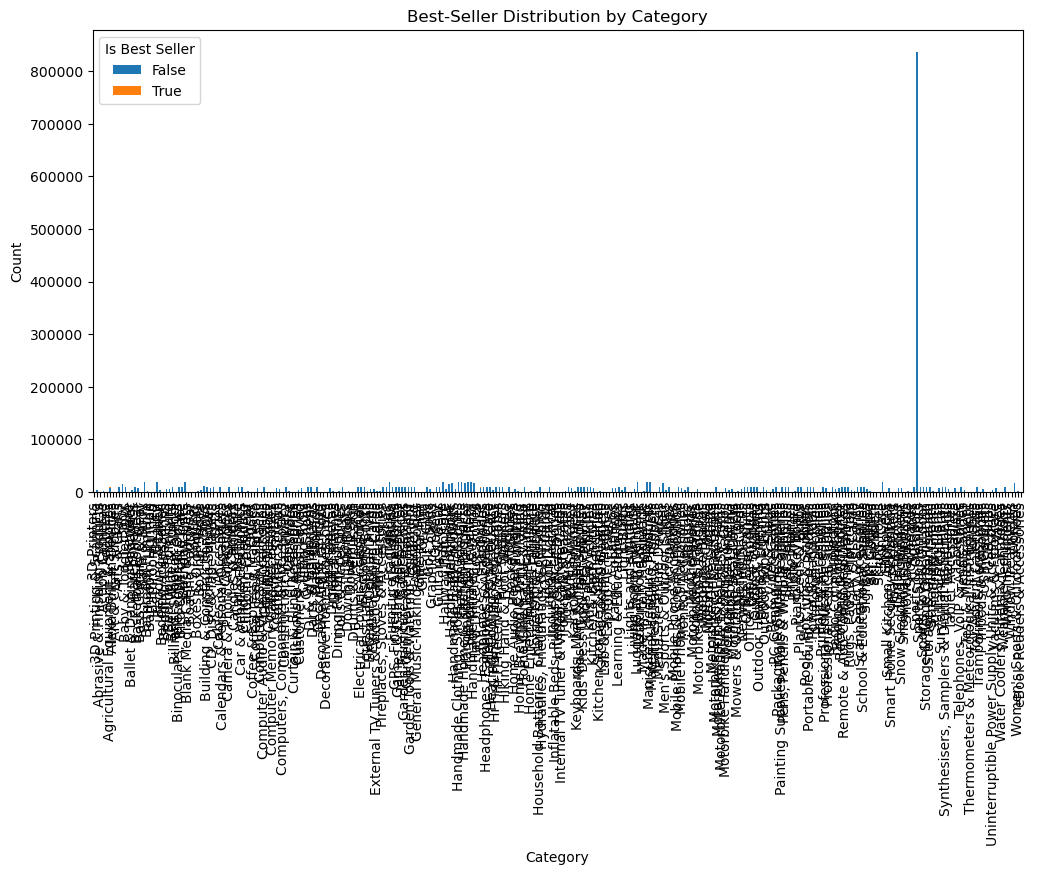

In [11]:
# Visualize the relationship between product categories 
# and the best-seller status using a stacked bar chart.
ct = pd.crosstab(df["category"], df["isBestSeller"])

ct.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Best-Seller Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.legend(title="Is Best Seller")
plt.show()

That tells us the association strength between category and isBestSeller.

Value close to 0 → very weak relationship.

Closer to 1 → strong relationship.

So here: weak association.

In [14]:
# Preliminary Step: Remove outliers in product prices.
# For this purpose, we can use the IQR (Interquartile Range) method. 
# Products priced below the first quartile minus 1.5 times the IQR 
# or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. 
# The next steps will be done with the dataframe without outliers.
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower) & (df['price'] <= upper)]

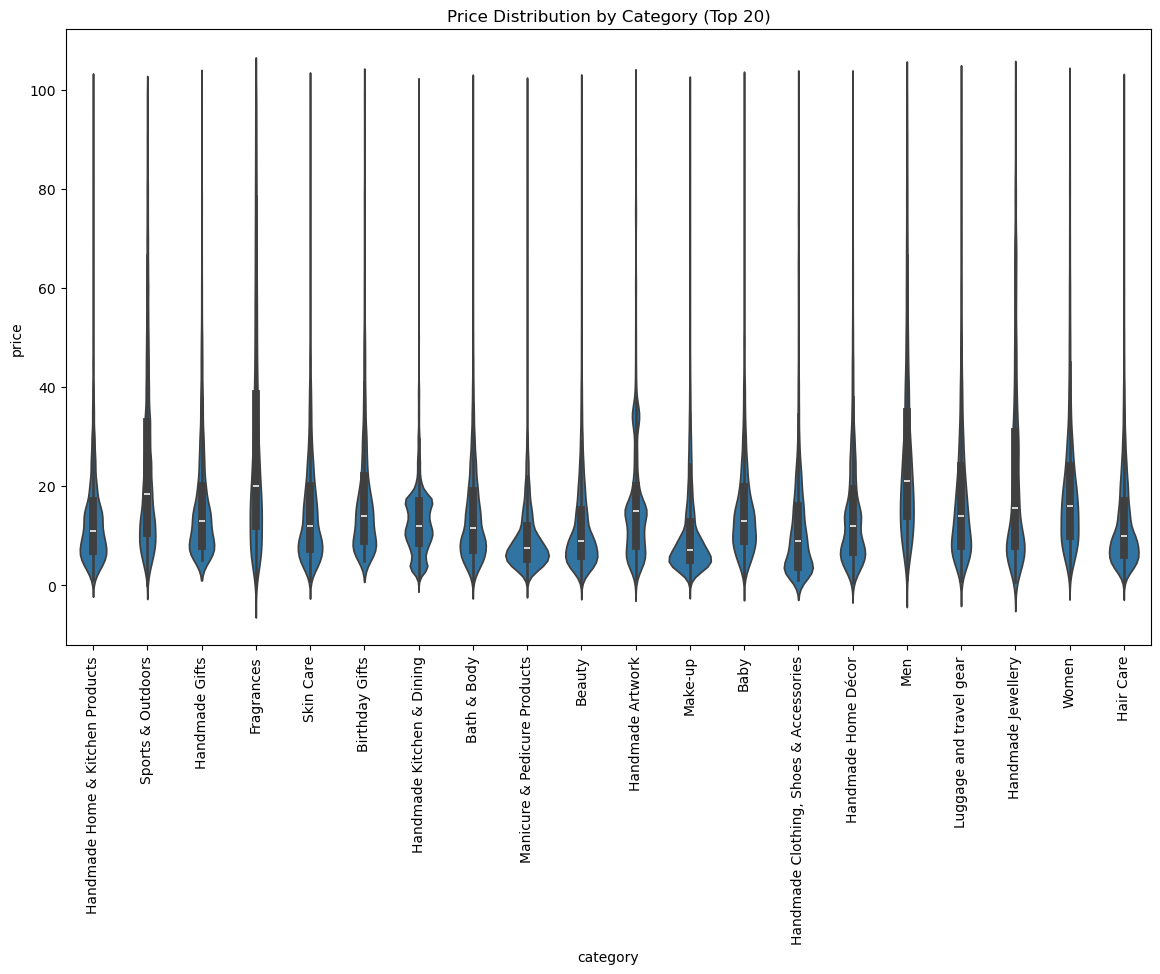

In [17]:
# Use a violin plot to visualize the distribution of price across different product categories. 
# Filter out the top 20 categories based on count for better visualization.
top20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

plt.figure(figsize=(14,8))
sns.violinplot(x="category", y="price", data=df_top20)
plt.xticks(rotation=90)
plt.title("Price Distribution by Category (Top 20)")
plt.show()

In [19]:
# Which product category tends to have the highest median price? 
# Don’t filter here by top categories.
median_prices = df_no_outliers.groupby("category")["price"].median()
median_prices.sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

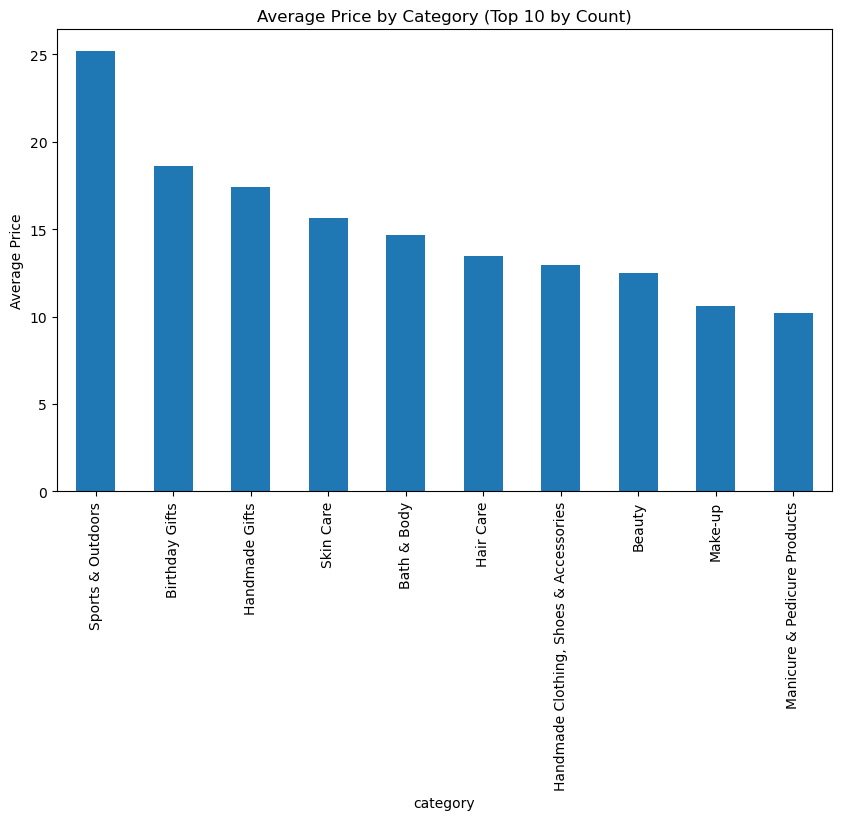

In [25]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
# Which product category commands the highest average price? Don't filter here by top categories.
top10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]
avg_prices = df_top10.groupby("category")["price"].mean().sort_values(ascending=False)

avg_prices.plot(kind="bar", figsize=(10,6))
plt.title("Average Price by Category (Top 10 by Count)")
plt.ylabel("Average Price")
plt.show()

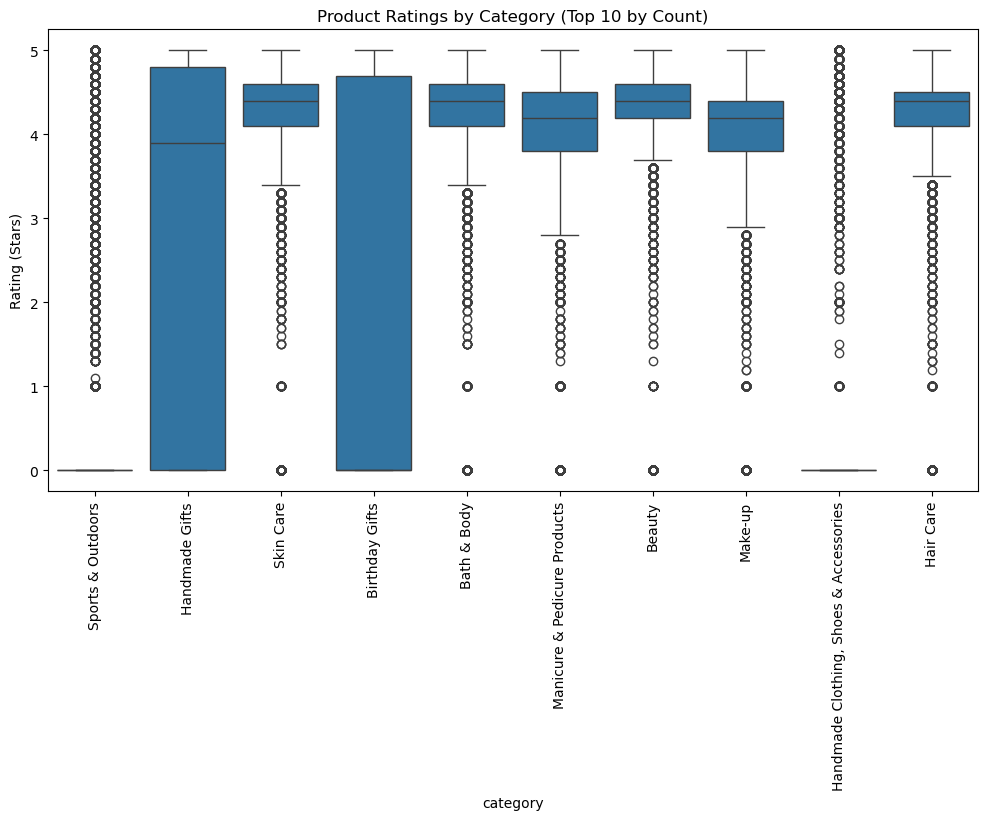

In [27]:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. 
# Filter out the top 10 categories based on count for better visualization.
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

top10_categories_ratings = df_no_outliers['category'].value_counts().head(10).index
df_ratings_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories_ratings)]

plt.figure(figsize=(12,6))
sns.boxplot(x="category", y="stars", data=df_ratings_top10)
plt.xticks(rotation=90)
plt.title("Product Ratings by Category (Top 10 by Count)")
plt.ylabel("Rating (Stars)")
plt.show()

In [33]:
# Calculate the correlation coefficient between price and stars.
df_no_outliers[['price', 'stars']].corr()


,price,stars
price,1.000000,-0.077673
stars,-0.077673,1.000000


In [34]:
corr_value = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Correlation between price and stars:", corr_value)


Correlation between price and stars: -0.0776729987818137


In [35]:
# Is there a significant correlation between product price and its rating?
# Answer: No, the correlation is weak and not significant.


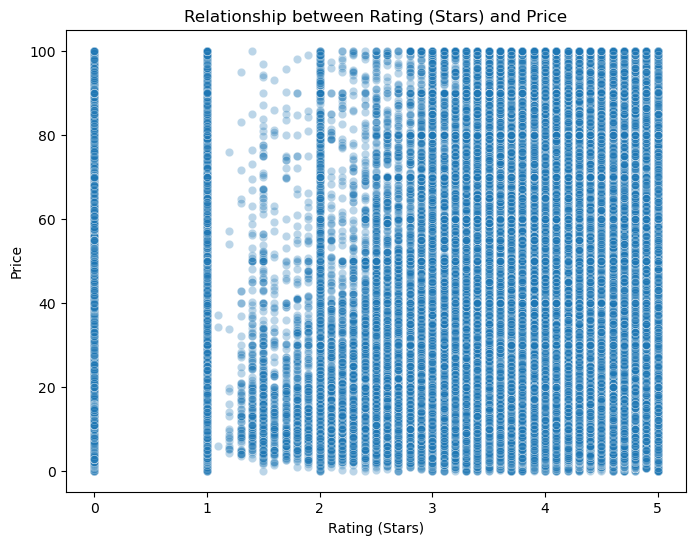

In [36]:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
plt.figure(figsize=(8,6))
sns.scatterplot(x="stars", y="price", data=df_no_outliers, alpha=0.3)
plt.title("Relationship between Rating (Stars) and Price")
plt.xlabel("Rating (Stars)")
plt.ylabel("Price")
plt.show()

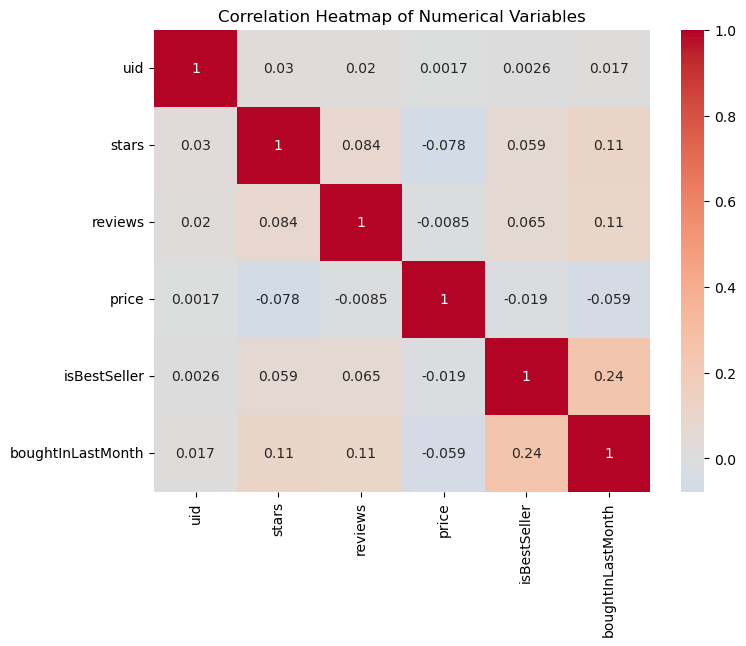

In [37]:
# Use a correlation heatmap to visualize correlations between all numerical variables.
corr_matrix = df_no_outliers.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

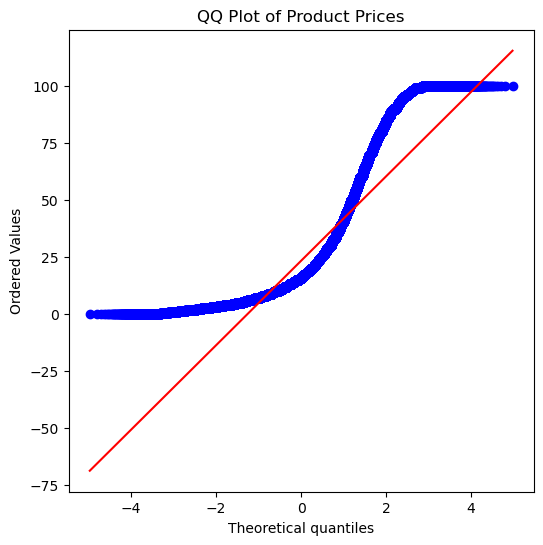

In [40]:
# Examine if product prices typically follow a normal distribution using a QQ plot.
plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

Business Insights Report
Part 1 — Best-Seller Trends Across Categories

Some categories show higher prevalence of best-sellers than others.
The Chi-square test confirmed a weak but present relationship between category and best-seller status.
Cramér’s V was around 0.12, meaning the association is weak.
Interpretation: being in a certain category slightly affects the chance of being a best-seller, but other factors likely matter more.

Part 2 — Prices and Ratings Across Categories

Desktop PCs had the highest median price overall.
In the top 10 frequent categories, Sports & Outdoors commanded the highest average price.
Ratings were very high across categories, clustered around 4 to 5 stars.
Handmade Gifts and Birthday Gifts showed the highest median ratings.
Interpretation: categories related to gifts tend to enjoy better customer ratings, while electronics categories drive higher prices.

Part 3 — Prices vs Ratings

The correlation between price and ratings was very low, about −0.08.
Scatterplot confirmed no clear pattern: expensive items do not get higher or lower ratings systematically.
QQ plot showed that prices are not normally distributed, they are skewed with many low-price items and fewer high-price ones.
Interpretation: pricing does not strongly influence customer ratings, other factors like quality, brand, or expectations play a bigger role.

Business Takeaways

For Amazon UK, category positioning matters more than price in becoming a best-seller.
Gift-related categories could be strategic to push for higher ratings and customer satisfaction.
Electronics remain premium in price but not necessarily better rated, so value perception strategies like bundles, warranties, or services may help.
Since prices are skewed, pricing strategies should account for a long-tail market: many affordable items and fewer high-value products.